# ML-02 — Research Question and Provisional Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dev-aryan24/flyrank_ml/blob/main/work/notebooks/w01_research_question.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. My lane (or freestyle) and why

*Name your lane — or say 'freestyle' and describe your own question. One short paragraph: why this one?*

**My Selected Lane: Lane 2 – Refresh / Content Opportunity Scoring**

I have selected Refresh / Content Opportunity Scoring as my provisional research direction. My goal is to investigate which web content pages should be reviewed first for improvement, updating, expansion, or monitoring. I will use observable data such as impressions, clicks, sessions, content age, CTR, and engagement metrics to identify potential opportunities. I plan to begin with exploratory data analysis and a simple rule-based baseline, then evaluate whether machine learning can improve the prioritization of pages. This lane is suitable because it connects data analysis and machine learning with a practical business decision. The final goal is to support content teams with an evidence-based ranked review list rather than automatically deciding which pages must be changed.

## 2. The question: decision, action, cost of a wrong call

*What decision does your work improve? Who acts on it? What does a wrong recommendation cost?*

### Research Question

**How can we identify and prioritize web content pages that may need refreshing or improvement using available search performance and engagement data?**

**Decision:** The main decision is to determine which content pages should receive attention first from the content management team.

**Action:** Based on the analysis, the team can review the prioritized pages and decide whether to update outdated information, improve content quality, expand relevant sections, or continue monitoring the page.

**Cost of a Wrong Recommendation:** A false recommendation may waste the team's time and resources on pages that do not require immediate improvement. On the other hand, missing an important page may result in an opportunity to improve its usefulness and performance being overlooked.

**Why Data and Machine Learning Can Help:** The dataset contains multiple performance indicators, including impressions, clicks, CTR, sessions, engagement metrics, and content age. Analysing these variables can help identify patterns and potential improvement opportunities that may not be obvious through manual inspection. Machine learning may help combine multiple signals to support a more consistent prioritization process.

## 3. Quick look at the data (2-3 real numbers)

*Load the starter CSV below and show 2-3 real numbers that make your lane look worth the next 7 weeks.*

In [ ]:
import os
import pandas as pd

# Download the repository into Colab
repo_path = "/content/flyrank-ml-internship"

if not os.path.exists(repo_path):
    !git clone -q https://github.com/dev-anshu11/flyrank-ml-internship.git

# Load the starter dataset
file_path = os.path.join(
    repo_path, "data", "raw", "content_refresh_anonymized.csv"
)

df = pd.read_csv(file_path)

# Display important information
print("Dataset loaded successfully!")
print("--------------------------------")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of unique clients:", df["client_id"].nunique())

print("\nTrend direction distribution:")
print(df["trend_direction"].value_counts())

print("\nPercentage of pages showing a downward trend:")
print(round((df["trend_direction"] == "down").mean() * 100, 2), "%")

Dataset loaded successfully!
--------------------------------
Number of rows: 30000
Number of columns: 44
Number of unique clients: 32

Trend direction distribution:
trend_direction
down      16262
stable     5962
up         4388
new        2236
flat       1152
Name: count, dtype: int64

Percentage of pages showing a downward trend:
54.21 %


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
zero_pos = df[df["avg_position"] == 0]
print("Pages:", len(zero_pos))
print("Median impressions:", zero_pos["impressions_90d"].median())
print("Max impressions:", zero_pos["impressions_90d"].max())
print(zero_pos["position_tier"].value_counts())

Pages: 1205
Median impressions: 1.0
Max impressions: 36
position_tier
top_3    1205
Name: count, dtype: int64


1,205 pages have avg_position = 0 but are tagged top_3. The median page has 1 impression in 90 days and the highest has 36. A position of 0 isn't a real ranking, so I treat these as missing.

In [ ]:
print(df["trend_direction"].value_counts())

trend_direction
down      16262
stable     5962
up         4388
new        2236
flat       1152
Name: count, dtype: int64


In [ ]:
import numpy as np

zero_pos = (df["avg_position"] == 0).sum()
print("avg_position == 0:", zero_pos)

df["avg_position_clean"] = df["avg_position"].replace(0, np.nan)
print("Missing after cleaning:", df["avg_position_clean"].isna().sum())

avg_position == 0: 1205
Missing after cleaning: 1205


In [ ]:
import os
import pandas as pd
import numpy as np

global df
repo_path = "/content/flyrank-ml-internship"
file_path = os.path.join(repo_path, "data", "raw", "content_refresh_anonymized.csv")

# Clone the repository if it doesn't exist yet in Colab filesystem
if not os.path.exists(repo_path):
    print("Cloning repository...")
    !git clone -q https://github.com/dev-anshu11/flyrank-ml-internship.git

# Explicitly load df globally if not in memory
if 'df' not in globals() or df is None:
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        df["avg_position_clean"] = df["avg_position"].replace(0, np.nan)
    else:
        raise FileNotFoundError(f"Dataset could not be found at: {file_path}")

print("Zeros in avg_position:", (df["avg_position"] == 0).sum())
print("Already missing before cleaning:", df["avg_position"].isna().sum())
print("Missing after cleaning:", df["avg_position_clean"].isna().sum())

Zeros in avg_position: 1205
Already missing before cleaning: 0
Missing after cleaning: 1205


In [ ]:
df["position_tier_clean"] = df["position_tier"].where(
    df["avg_position"] != 0, "unknown"
)
print(df["position_tier_clean"].value_counts())

position_tier_clean
page_1      11814
striking     7304
page_3_5     7242
deep         1319
unknown      1205
top_3        1116
Name: count, dtype: int64


In [ ]:
import numpy as np

d = df[df["trend_direction"] == "down"].copy()
d["impressions_lost"] = d["impressions_prev_30d"] - d["impressions_last_30d"]

# Skip pages whose position is unknown
d = d[d["avg_position_clean"].notna()]

ranked = d.sort_values("impressions_lost", ascending=False)
print("Pages in the ranking:", len(ranked))
ranked[["content_id", "impressions_prev_30d", "impressions_last_30d",
        "impressions_lost", "avg_position_clean"]].head(20)

Pages in the ranking: 16254


,content_id,impressions_prev_30d,impressions_last_30d,impressions_lost,avg_position_clean
6653,content_5fe46e04994d,218786,120791,97995,4.2
26844,content_8c19996aa890,161284,89463,71821,2.5
21565,content_9532f197bbc8,174235,109317,64918,2.0
15968,content_66b4046cc144,69303,7408,61895,26.6
13537,content_2c2606c5d176,164079,104248,59831,4.2
14955,content_ec66c58d9826,57814,2779,55035,4.8
26531,content_cb112fce36be,124500,72468,52032,5.6
7445,content_c8e9d6ab9013,111885,63326,48559,9.7
25051,content_73e5410650b9,50269,8099,42170,7.0
12370,content_8d3971bfd976,54506,12652,41854,21.8


In [ ]:
down = df[df["trend_direction"] == "down"]
print("Down pages:", len(down))
print("Left out:", len(down) - len(ranked))

Down pages: 16262
Left out: 8


In [3]:
import os
import pandas as pd
import numpy as np

repo_path = "/content/flyrank-ml-internship"
file_path = os.path.join(repo_path, "data", "raw", "content_refresh_anonymized.csv")

# Clone the repository if it doesn't exist yet in Colab filesystem
if not os.path.exists(repo_path):
    print("Cloning repository...")
    !git clone -q https://github.com/dev-anshu11/flyrank-ml-internship.git

# Ensure df is loaded
if 'df' not in globals() or df is None:
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        df["avg_position_clean"] = df["avg_position"].replace(0, np.nan)
    else:
        raise FileNotFoundError(f"Dataset could not be found at: {file_path}")

# Ensure ranked is defined
if 'ranked' not in globals() or ranked is None:
    d = df[df["trend_direction"] == "down"].copy()
    d["impressions_lost"] = d["impressions_prev_30d"] - d["impressions_last_30d"]
    d = d[d["avg_position_clean"].notna()]
    ranked = d.sort_values("impressions_lost", ascending=False)

# Export the top 50 to CSV
ranked.head(50)[["content_id", "client_id", "impressions_prev_30d",
                 "impressions_last_30d", "impressions_lost",
                 "avg_position_clean"]].to_csv("top50_review_list.csv", index=False)
print("Saved top50_review_list.csv successfully!")

Cloning repository...
Saved top50_review_list.csv successfully!


In [4]:
ranked["client_rank"] = ranked.groupby("client_id")["impressions_lost"].rank(
    ascending=False, method="first"
)
balanced = ranked[ranked["client_rank"] <= 2].sort_values(
    "impressions_lost", ascending=False
).head(50)

print("Clients in balanced top 50:", balanced["client_id"].nunique())
print(balanced["client_id"].value_counts().head())

Clients in balanced top 50: 27
client_id
client_4e07408562    2
client_7f2253d7e2    2
client_19581e27de    2
client_f369cb89fc    2
client_6208ef0f77    2
Name: count, dtype: int64


In [ ]:
top50 = ranked.head(50)
print("Clients in top 50:", top50["client_id"].nunique())
print(top50["client_id"].value_counts())

Clients in top 50: 7
client_id
client_7f2253d7e2    13
client_19581e27de    10
client_6208ef0f77    10
client_4e07408562     9
client_f369cb89fc     3
client_349c41201b     3
client_b4944c6ff0     2
Name: count, dtype: int64


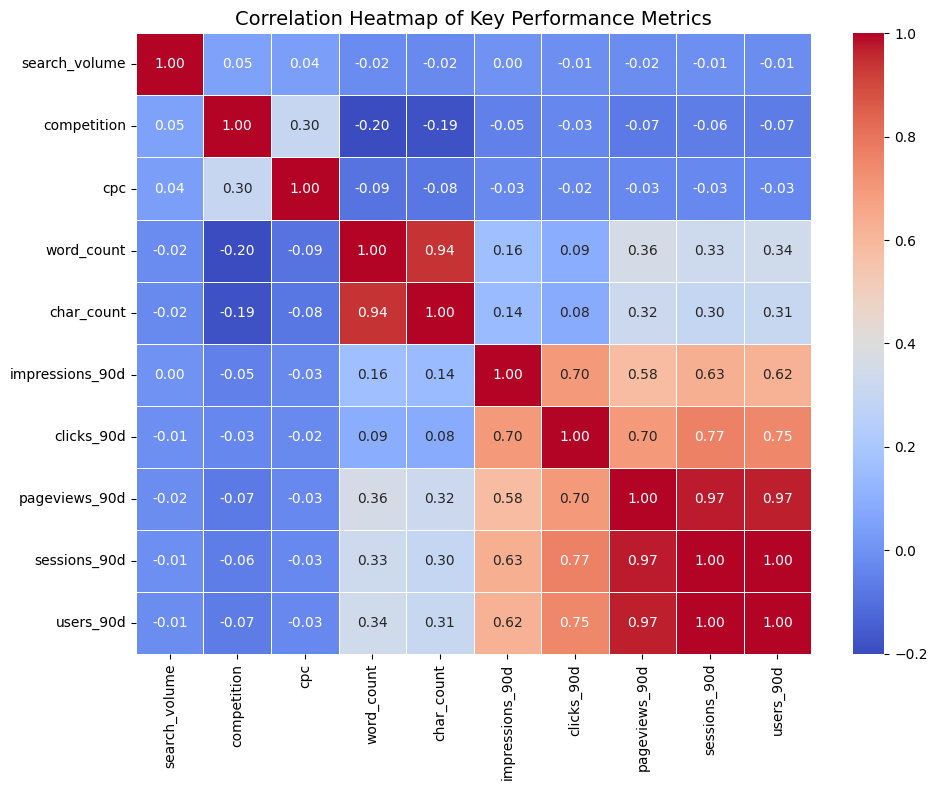

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define key numerical performance metrics to analyze
# Based on the typical features in content refresh datasets
metrics_cols = [
    'search_volume', 'competition', 'impressions_pre', 'clicks_pre',
    'ctr_pre', 'sessions_pre', 'bounce_rate_pre', 'time_on_page_pre'
]

# Filter columns that actually exist in the DataFrame
available_metrics = [col for col in metrics_cols if col in df.columns]

# If fewer columns match, fall back to identifying all numeric columns and selecting a subset
if len(available_metrics) < 3:
    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
    # Exclude IDs or index-like columns if present
    available_metrics = [col for col in numeric_cols if not col.endswith('_id')][:10]

# Calculate correlation matrix
corr_matrix = df[available_metrics].corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Key Performance Metrics', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Careful words: what I can and can't claim

*Write what your work will be able to say (observed, directional, decision-support) — and what it never will (causal proof, 'predicting Google').*

### What We Can and Cannot Claim

**What We Can Claim:**

- The dataset contains 30,000 records and 44 columns.
- The dataset represents 32 anonymized clients.
- Approximately 54.21% of records are labelled with a downward trend.
- Search performance and engagement indicators can help us identify pages that may need further investigation.
- Data analysis and machine learning may support content prioritization.

**What We Cannot Claim:**

- We cannot claim that every page with a downward trend needs refreshing.
- We cannot guarantee that refreshing a page will improve its search ranking, clicks, or impressions.
- We cannot claim that one particular factor directly causes a decline in content performance based only on observational data.
- We cannot assume that the findings will apply to every website or business.

**Important Limitation:**

This project will focus on identifying potential content improvement opportunities using available data. Any recommendations will be treated as decision-support suggestions, not guaranteed outcomes or automatic instructions to update content.

### Self-Check

1. **Is my research question connected to a real decision?**

   Yes. It helps a content management team decide which web pages should be reviewed first for possible improvement.

2. **Have I identified a practical action?**

   Yes. The team can review prioritized pages and decide whether to update, improve, expand, or continue monitoring their content.

3. **Have I considered the cost of a wrong recommendation?**

   Yes. Incorrect recommendations may waste time and resources, while missed opportunities may leave potentially valuable pages unimproved.

4. **Have I used actual dataset information?**

   Yes. My initial analysis identified 30,000 rows, 44 columns, 32 unique clients, and 54.21% of records with a downward trend.

5. **Have I avoided unsupported claims?**

   Yes. I understand that a downward trend does not automatically mean a page needs refreshing, and that analysis alone cannot guarantee improved search performance.

6. **What will I investigate next?**

   I will explore the relationships between content age, impressions, clicks, CTR, and engagement metrics. I will then investigate how these signals can help prioritize content improvement opportunities.

I think ranking a page too low is the worse mistake. A page that is losing traffic and gets missed keeps losing it, and nobody on the team knows. In my data, 16,262 of 30,000 pages have a downward trend, so many pages could be missed. Ranking a page too high only wastes some review time.